# Diabetis Prediction

# Health Indicators and Diabetes Prediction Using Logistic Regression
#### Predicting Diabetes using Logistic Regression based on health behaviors, physical/mental condition, and demographics
#### Data Source - CDC's BRFSS2015 Dataset downloaded from Kaggle.com



In [29]:
import pandas as pd
import numpy as np
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.linear_model import LogisticRegression
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, confusion_matrix, classification_report, RocCurveDisplay
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

### Load the Data

In [10]:
df=pd.read_csv("diabetes_binary_5050split_health_indicators_BRFSS2015.csv")
df

,Diabetes_binary,HighBP,HighChol,CholCheck,BMI,Smoker,Stroke,HeartDiseaseorAttack,PhysActivity,Fruits,...,AnyHealthcare,NoDocbcCost,GenHlth,MentHlth,PhysHlth,DiffWalk,Sex,Age,Education,Income
0,0.0,1.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,3.0,5.0,30.0,0.0,1.0,4.0,6.0,8.0
1,0.0,1.0,1.0,1.0,26.0,1.0,1.0,0.0,0.0,1.0,...,1.0,0.0,3.0,0.0,0.0,0.0,1.0,12.0,6.0,8.0
2,0.0,0.0,0.0,1.0,26.0,0.0,0.0,0.0,1.0,1.0,...,1.0,0.0,1.0,0.0,10.0,0.0,1.0,13.0,6.0,8.0
3,0.0,1.0,1.0,1.0,28.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,3.0,0.0,3.0,0.0,1.0,11.0,6.0,8.0
4,0.0,0.0,0.0,1.0,29.0,1.0,0.0,0.0,1.0,1.0,...,1.0,0.0,2.0,0.0,0.0,0.0,0.0,8.0,5.0,8.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
70687,1.0,0.0,1.0,1.0,37.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,4.0,0.0,0.0,0.0,0.0,6.0,4.0,1.0
70688,1.0,0.0,1.0,1.0,29.0,1.0,0.0,1.0,0.0,1.0,...,1.0,0.0,2.0,0.0,0.0,1.0,1.0,10.0,3.0,6.0
70689,1.0,1.0,1.0,1.0,25.0,0.0,0.0,1.0,0.0,1.0,...,1.0,0.0,5.0,15.0,0.0,1.0,0.0,13.0,6.0,4.0
70690,1.0,1.0,1.0,1.0,18.0,0.0,0.0,0.0,0.0,0.0,...,1.0,0.0,4.0,0.0,0.0,1.0,0.0,11.0,2.0,4.0


In [11]:
#Missing values
df.isna().sum()

Diabetes_binary         0
HighBP                  0
HighChol                0
CholCheck               0
BMI                     0
Smoker                  0
Stroke                  0
HeartDiseaseorAttack    0
PhysActivity            0
Fruits                  0
Veggies                 0
HvyAlcoholConsump       0
AnyHealthcare           0
NoDocbcCost             0
GenHlth                 0
MentHlth                0
PhysHlth                0
DiffWalk                0
Sex                     0
Age                     0
Education               0
Income                  0
dtype: int64

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 70692 entries, 0 to 70691
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Diabetes_binary       70692 non-null  float64
 1   HighBP                70692 non-null  float64
 2   HighChol              70692 non-null  float64
 3   CholCheck             70692 non-null  float64
 4   BMI                   70692 non-null  float64
 5   Smoker                70692 non-null  float64
 6   Stroke                70692 non-null  float64
 7   HeartDiseaseorAttack  70692 non-null  float64
 8   PhysActivity          70692 non-null  float64
 9   Fruits                70692 non-null  float64
 10  Veggies               70692 non-null  float64
 11  HvyAlcoholConsump     70692 non-null  float64
 12  AnyHealthcare         70692 non-null  float64
 13  NoDocbcCost           70692 non-null  float64
 14  GenHlth               70692 non-null  float64
 15  MentHlth           

In [ ]:
df

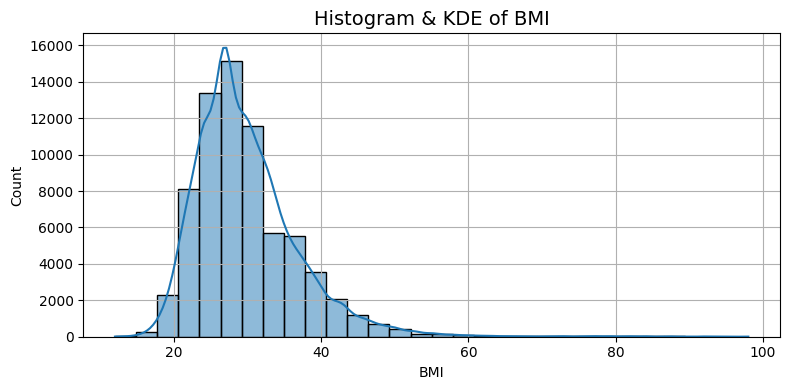

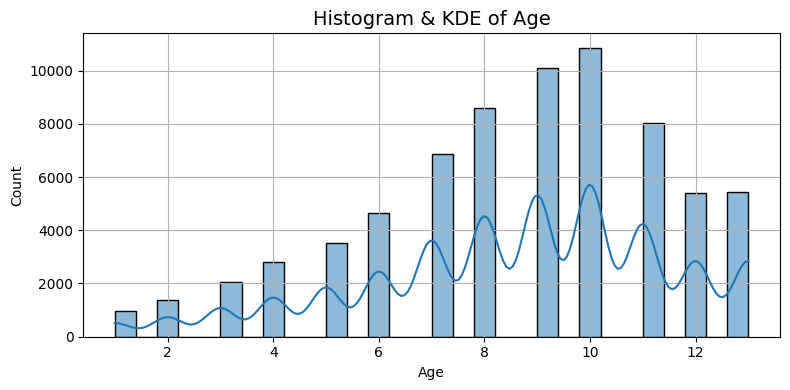

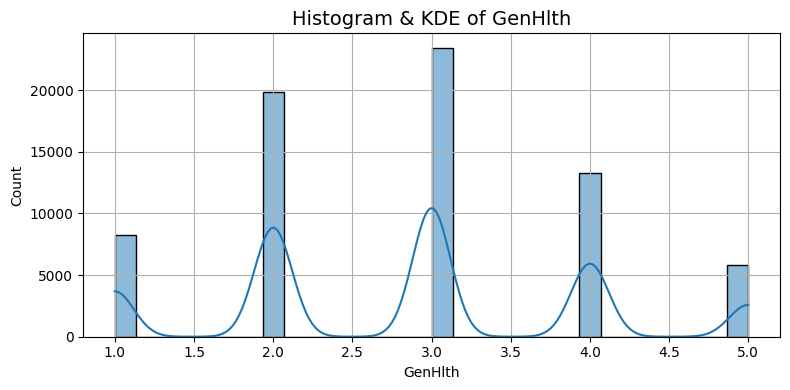

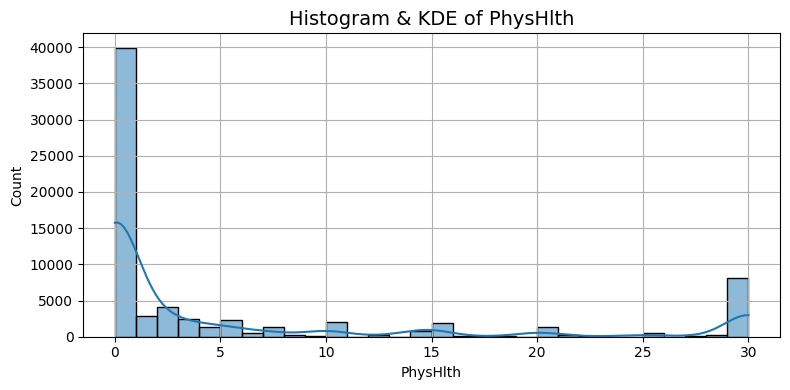

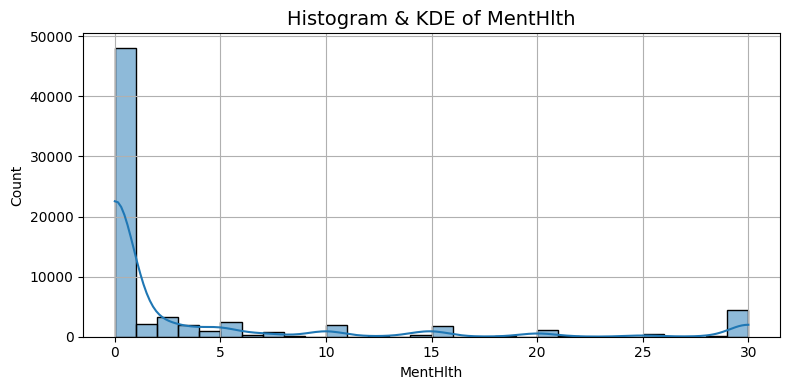

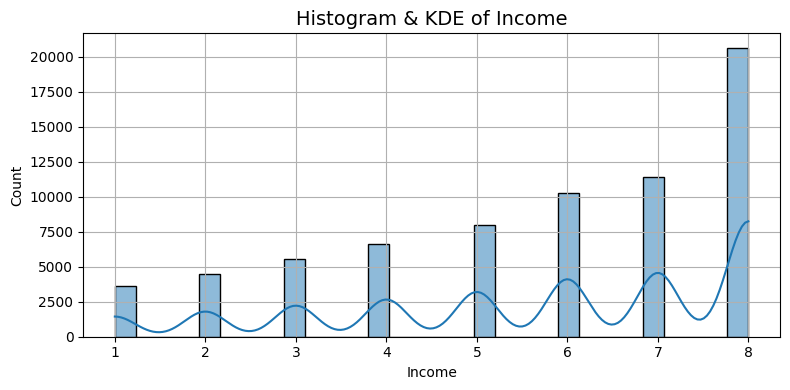

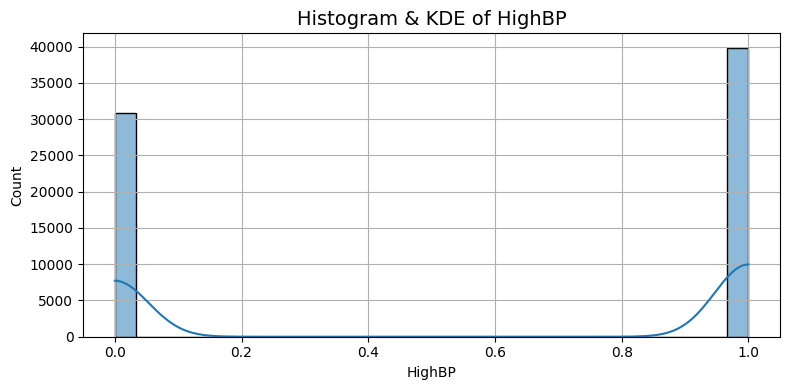

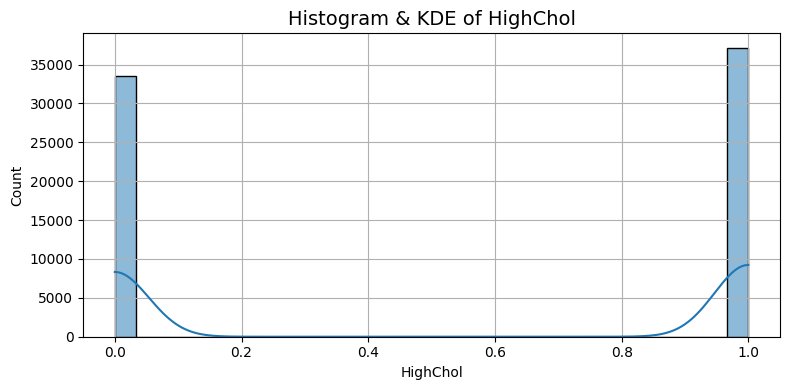

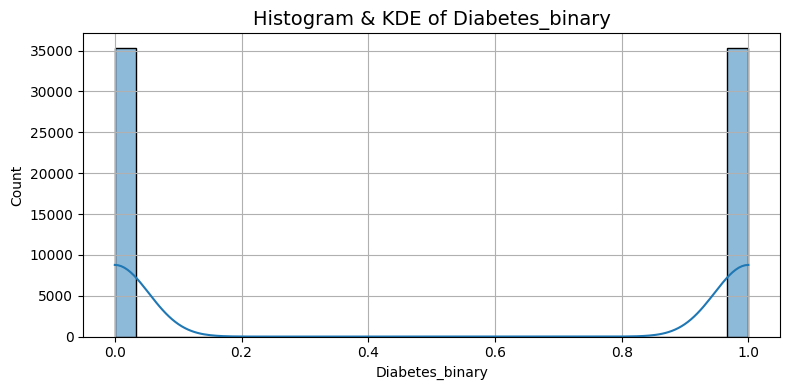

In [20]:
# Create simple histograms with KDE (no hue, no grouping) for selected features
selected_features = ['BMI', 'Age', 'GenHlth', 'PhysHlth', 'MentHlth', 'Income', 'HighBP', 'HighChol', 'Diabetes_binary']

# Plot simple histogram with KDE for each feature
for feature in selected_features:
    plt.figure(figsize=(8, 4))
    sns.histplot(df[feature], kde=True, bins=30,  edgecolor='black')
    plt.title(f"Histogram & KDE of {feature}", fontsize=14)
    plt.xlabel(feature)
    plt.ylabel("Count")
    plt.grid(True)
    plt.tight_layout()
    plt.show()

#### The dataset is clean, and includes 70,692 records with no missing values.

### Correlation Plot

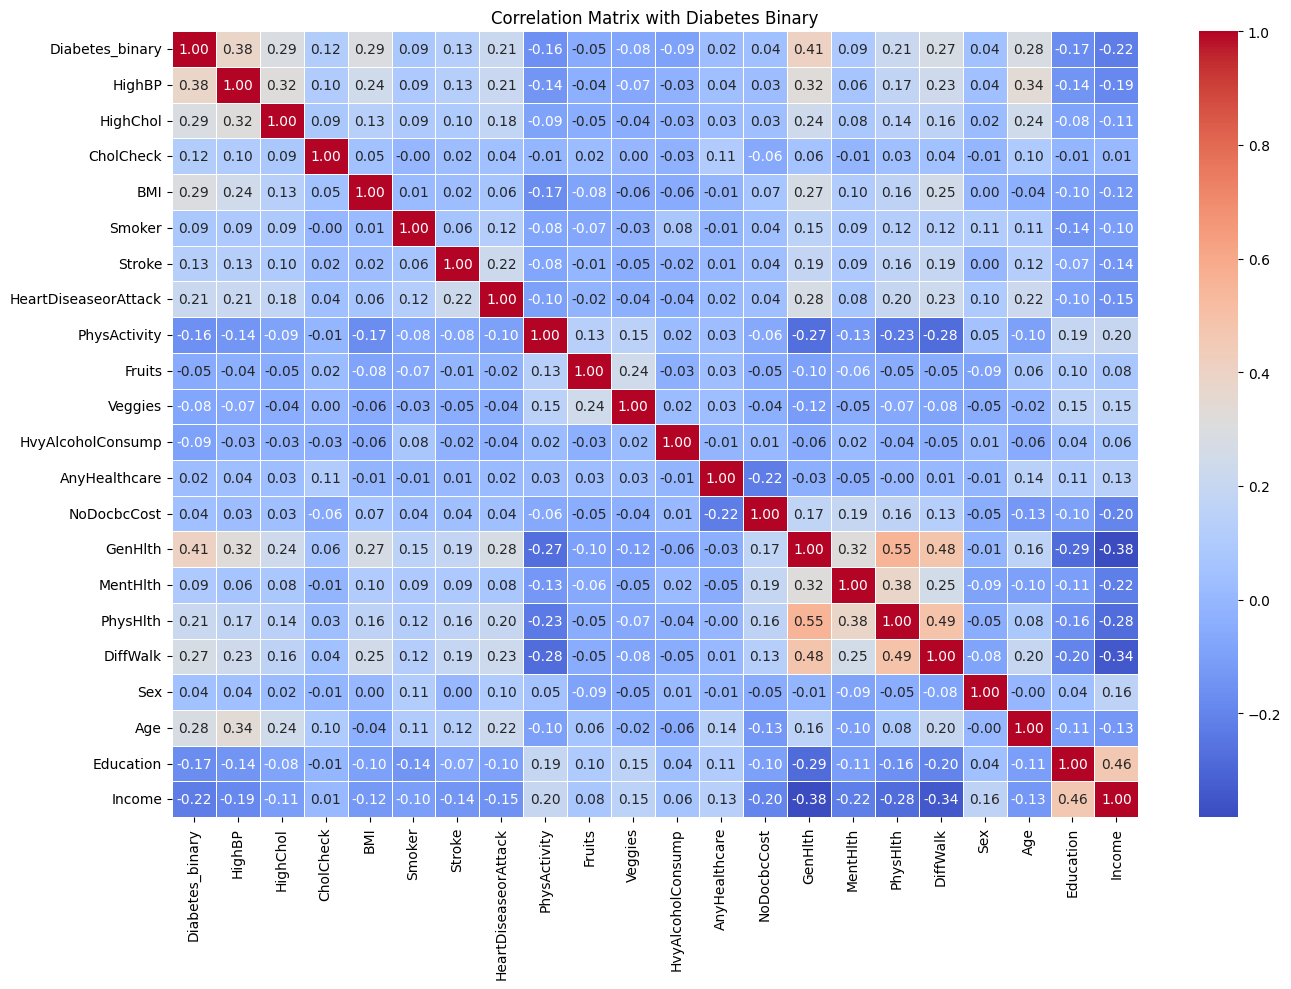

In [56]:
# Compute correlation matrix
correlation_matrix = df.corr()

# Plot heatmap of correlation matrix
plt.figure(figsize=(14, 10))
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap="coolwarm", linewidths=0.5)
plt.title("Correlation Matrix with Diabetes Binary")
plt.tight_layout()
plt.show()

In [21]:
# Separate features and target
X = df.drop(columns='Diabetes_binary')
y = df['Diabetes_binary']


In [24]:
# Split into train/test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=68)

In [27]:
# Standardize features
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [30]:
# Fit logistic regression
log_reg = LogisticRegression(max_iter=1000)
log_reg.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [32]:
# Predictions
y_pred = log_reg.predict(X_test_scaled)
y_proba = log_reg.predict_proba(X_test_scaled)[:, 1]

In [33]:
# Evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)
conf_matrix = confusion_matrix(y_test, y_pred)
report = classification_report(y_test, y_pred, output_dict=True)

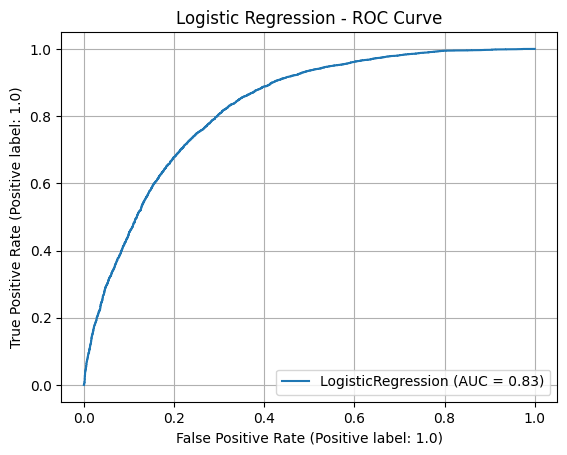

In [34]:
# Plot ROC Curve
RocCurveDisplay.from_estimator(log_reg, X_test_scaled, y_test)
plt.title("Logistic Regression - ROC Curve")
plt.grid(True)
plt.show()

In [36]:
print("Accuracy is: ",accuracy)

Accuracy is 0.7490628757337859


In [37]:
print("precision is: ",precision)

precision is:  0.7378495791474342


In [38]:
print("Recall is :",recall)

Recall is : 0.7707033465683494


In [39]:
print("f1 score is :",f1)

f1 score is : 0.7539187127202108


In [40]:
print("roc_auc: ", roc_auc)

roc_auc:  0.8262662231926495


In [41]:
print("confusion matrix: ",conf_matrix)

confusion matrix:  [[5156 1931]
 [1617 5435]]


In [42]:
 print("classification report: ",report)

classification report:  {'0.0': {'precision': 0.7612579359220434, 'recall': 0.7275292789614788, 'f1-score': 0.744011544011544, 'support': 7087.0}, '1.0': {'precision': 0.7378495791474342, 'recall': 0.7707033465683494, 'f1-score': 0.7539187127202108, 'support': 7052.0}, 'accuracy': 0.7490628757337859, 'macro avg': {'precision': 0.7495537575347389, 'recall': 0.7491163127649141, 'f1-score': 0.7489651283658774, 'support': 14139.0}, 'weighted avg': {'precision': 0.7495827303223161, 'recall': 0.7490628757337859, 'f1-score': 0.7489528661512652, 'support': 14139.0}}


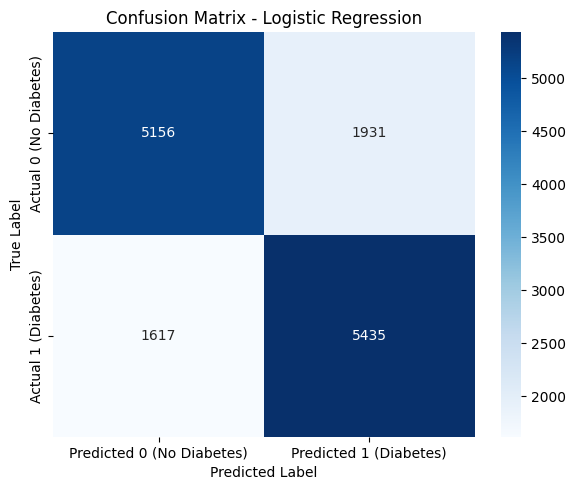

In [44]:
# Plot the confusion matrix using seaborn heatmap
plt.figure(figsize=(6, 5))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Predicted 0 (No Diabetes)', 'Predicted 1 (Diabetes)'],
            yticklabels=['Actual 0 (No Diabetes)', 'Actual 1 (Diabetes)'])
plt.title("Confusion Matrix - Logistic Regression")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()

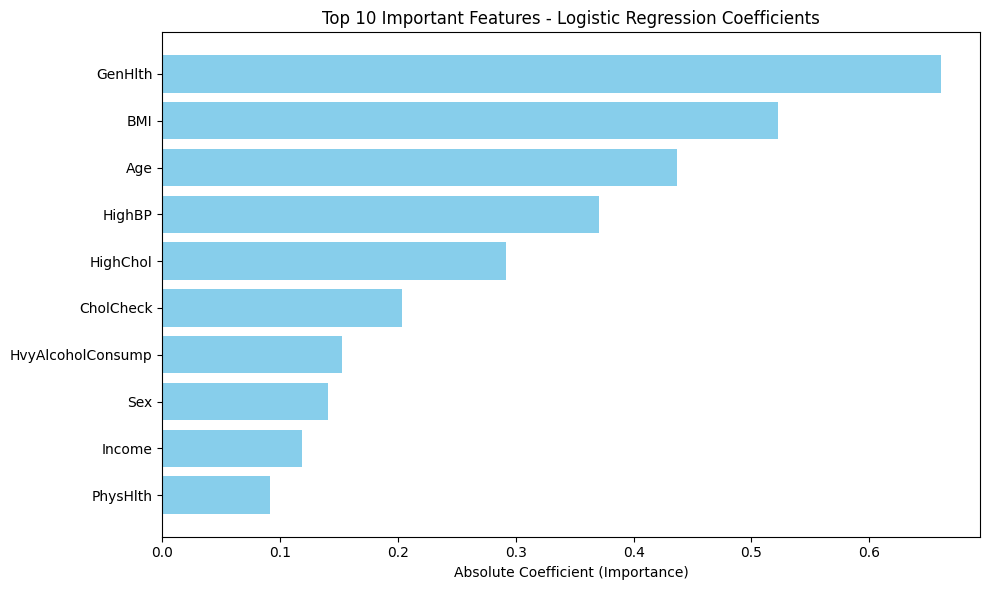

In [55]:
# Get feature names and model coefficients
features = X.columns
coefficients = log_reg.coef_[0]
odds_ratios = np.exp(coefficients)

# Create DataFrame and sort by absolute coefficient
importance_df = pd.DataFrame({
    'Feature': features,
    'Coefficient': coefficients,
    'Abs_Coefficient': np.abs(coefficients),
    'Odds_Ratio': odds_ratios
}).sort_values(by='Abs_Coefficient', ascending=False)

# Select top 10 features
top_features = importance_df.head(10)

# Plot horizontal bar chart
plt.figure(figsize=(10, 6))
plt.barh(top_features['Feature'], top_features['Abs_Coefficient'], color='skyblue')
plt.xlabel("Absolute Coefficient (Importance)")
plt.title("Top 10 Important Features - Logistic Regression Coefficients")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [61]:
# Create DataFrame for odds ratios fro each features
odds_df = pd.DataFrame({
    'Feature': features,
    'Coefficient': coefficients,
    'Odds_Ratio': odds_ratios
}).sort_values(by='Odds_Ratio', ascending=False)

print(odds_df)

                 Feature  Coefficient  Odds_Ratio
13               GenHlth     0.660953    1.936637
3                    BMI     0.522659    1.686506
18                   Age     0.437024    1.548093
0                 HighBP     0.370361    1.448257
1               HighChol     0.291264    1.338118
2              CholCheck     0.203413    1.225579
17                   Sex     0.140164    1.150463
6   HeartDiseaseorAttack     0.088182    1.092187
16              DiffWalk     0.052777    1.054194
5                 Stroke     0.035613    1.036255
11         AnyHealthcare     0.014233    1.014335
12           NoDocbcCost     0.005195    1.005208
4                 Smoker    -0.003975    0.996033
7           PhysActivity    -0.012452    0.987625
8                 Fruits    -0.013984    0.986114
9                Veggies    -0.023930    0.976354
14              MentHlth    -0.035106    0.965503
19             Education    -0.038920    0.961828
15              PhysHlth    -0.090910    0.913100


### Odds ratios > 1 -Increased risk (positive association)

### Odds ratios < 1 - Decreased risk (negative association)

### Values closer to 1 - Weak or minimal effect

### Predictions

In [60]:
y_pred = log_reg.predict(X_test_scaled)       
y_prob = log_reg.predict_proba(X_test_scaled)

# Show predicted class and probability for each test instance
predictions_df = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted': y_pred,
    'Probability': y_prob[:, 1]
})

predictions_df.head(20)  

,Actual,Predicted,Probability
0,0.0,0.0,0.376505
1,1.0,0.0,0.371947
2,1.0,1.0,0.821419
3,1.0,1.0,0.650821
4,1.0,1.0,0.682197
5,0.0,0.0,0.222246
6,1.0,1.0,0.787404
7,1.0,0.0,0.400122
8,1.0,1.0,0.895771
9,1.0,1.0,0.612418


In [ ]:
 In some cases, even when the true label is 1, the model predicts 0 if the probability is below the 0.5 threshold, which explains occasional misclassifications.

### Cross Validation with RandomForest Regression

In [62]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

# Initialize Random Forest model
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)  #model will build 100 decision trees and combine their predictions, sets seed for reproducibility

# Perform 5-fold cross-validation for accuracy and ROC AUC
cv_accuracy = cross_val_score(rf_model, X_scaled, y, cv=5, scoring='accuracy') #Splits the data into 5 parts (folds),trains the model on 4 parts and tests it on the 5th and repeats

cv_auc = cross_val_score(rf_model, X_scaled, y, cv=5, scoring='roc_auc')

# Average scores
avg_accuracy_rf = cv_accuracy.mean()
avg_auc_rf = cv_auc.mean()



In [63]:
print("cross validation accuracy mean: ",avg_accuracy_rf)
print("cross validation auc mean: ",avg_auc_rf)

cross validation accuracy mean:  0.7375659012541758
cross validation auc mean:  0.8094962332788669


### Random Forest can handle nonlinear interactions and feature importance, but it doesn’t seem to significantly outperform the simpler logistic model here

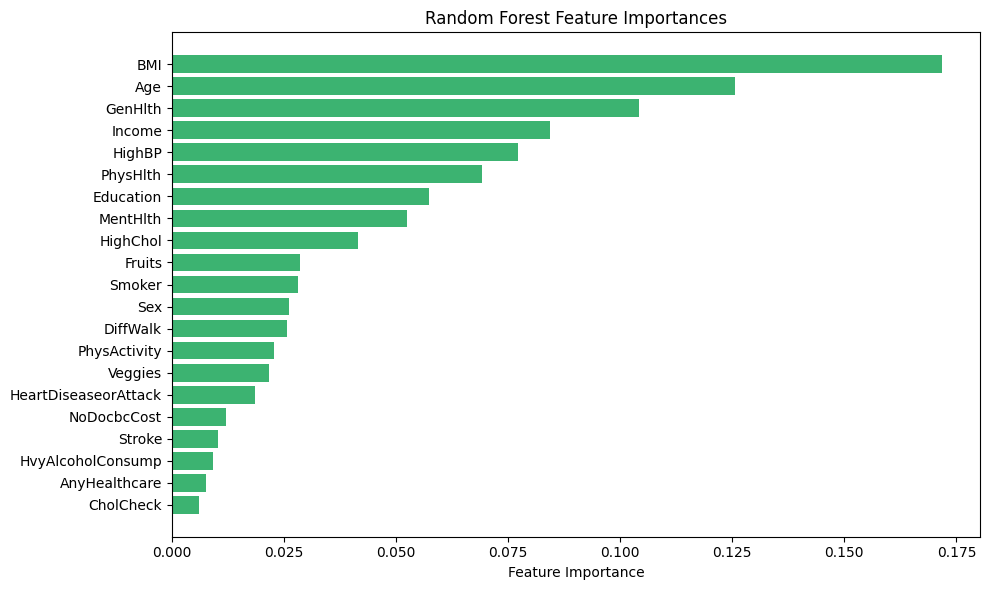

In [66]:
# Get feature importances
rf_model.fit(X_scaled, y)
importances = rf_model.feature_importances_
features = X.columns

# Create DataFrame for plotting
rf_importance_df = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=True)

# Plot the top features
plt.figure(figsize=(10, 6))
plt.barh(rf_importance_df['Feature'], rf_importance_df['Importance'], color='mediumseagreen')
plt.xlabel('Feature Importance')
plt.title('Random Forest Feature Importances')
plt.tight_layout()
plt.show()